# Computational Statistics Example Problems

**Reproducibility:** All random draws use one fixed NumPy seed. **Statistical assumptions and source issues:** Problem 1(b) does not specify a prior, so we explicitly choose a flat prior for the location parameter; Problem 3's stated conditional formulas are not normalized on the specified finite support, so we normalize them before constructing a valid Gibbs sampler. Problem 2 uses the `>10` category to avoid double-counting the displayed 10 category.

## 0. Setup

Install dependencies if needed with `python -m pip install numpy scipy matplotlib notebook nbformat`. We use NumPy for random numbers, SciPy for probability distributions, integration, and KDE, and Matplotlib for graphs. The notebook saves the same figures into `results/` while displaying them inline.

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from scipy.special import gammaln
from IPython.display import display, Image

OUT = Path('results')
OUT.mkdir(exist_ok=True)
RNG = np.random.default_rng(5722018)

def show_figure(name):
    display(Image(filename=str(OUT / name)))

print('Random seed: 5722018')

Random seed: 5722018


# Problem 1 — Extreme Value distribution

We are given the density

$$f(x\mid a,b)=\frac1b\exp\left(-\frac{x-a}{b}\right)\exp\left\{-\exp\left(-\frac{x-a}{b}\right)\right\},\quad b>0.$$

This is the *Gumbel distribution for maxima*. In part (a), the parameters are fixed at **$a=2,b=1$**, and we generate **$n=100$** observations.

## 1(a). Inverse-CDF simulation

**Step 1 — Find the cumulative distribution function.** Integrating the PDF gives

$$F(x)=\exp\left[-\exp\left(-\frac{x-a}{b}\right)\right].$$

**Step 2 — Solve $u=F(x)$ for $x$.** Taking logarithms twice gives

$$\ln u=-\exp(-(x-a)/b),\qquad x=a-b\ln(-\ln u).$$

**Step 3 — Generate data.** For each $i=1,\ldots,100$, generate $U_i\sim\operatorname{Uniform}(0,1)$ and calculate $X_i=2-\ln(-\ln U_i)$.

**Step 4 — Compare with truth.** Use a *density-normalized* histogram and overlay $f(x\mid 2,1)$. The empirical CDF is $\widehat F_n(t)=n^{-1}\sum_i\mathbf 1\{X_i\le t\}$; overlay the theoretical CDF. The Kolmogorov–Smirnov distance measures the maximum vertical gap.

In [2]:
def ev_pdf(x, a=2., b=1.):
    z = (np.asarray(x)-a)/b
    return np.exp(-z-np.exp(-z))/b

def ev_cdf(x, a=2., b=1.):
    return np.exp(-np.exp(-(np.asarray(x)-a)/b))

def ev_sample(n, a=2., b=1., rng=RNG):
    # Inverse CDF: F^{-1}(u) = a - b log(-log(u))
    u = rng.uniform(0, 1, n)
    return a - b*np.log(-np.log(u))

In [3]:
sample_preview = ev_sample(5, rng=np.random.default_rng(42))
print('Example of five inverse-transform draws:', np.round(sample_preview, 4))
print('These are demonstration draws using a separate generator.')

Example of five inverse-transform draws: [3.3616 2.1942 3.8809 3.0204 1.1402]
These are demonstration draws using a separate generator.


## 1(b). Estimate $a$ using a Markov chain

**Assumption (not specified in the exam):** $b=1$ is known, and we use an improper flat prior $p(a)\propto1$ on the real line. The resulting posterior is proper for $n\ge1$. Consequently, the requested interval is a **Bayesian 95% credible interval**, not a frequentist confidence interval.

**Step 1 — Likelihood:**

$$L(a\mid x)=\prod_{i=1}^n\exp[-(x_i-a)]\exp\{-\exp[-(x_i-a)]\}.$$

**Step 2 — Log posterior, omitting terms independent of $a$:**

$$\ell(a)=n a-e^a\sum_{i=1}^n e^{-x_i}+C.$$

**Step 3 — Choose Metropolis–Hastings (MH):** Start from the MLE

$$a_0=\log n-\log\left(\sum_i e^{-x_i}\right),$$

propose $a^*=a_t+\epsilon$, with $\epsilon\sim N(0,0.22^2)$, and accept with probability

$$\alpha=\min\{1,\exp[\ell(a^*)-\ell(a_t)]\}.$$

**Step 4 — Run:** 25,000 MH steps, remove the first 5,000 as burn-in; summarize the 20,000 retained values by their mean, standard deviation, and 2.5% / 97.5% quantiles.

**Step 5 — Analytic check:** Defining $S=\sum e^{-x_i}$ and $T=e^a$, one can derive $T\mid x\sim \operatorname{Gamma}(\text{shape}=n,\text{rate}=S)$. We overlay the exact transformed posterior density on the MCMC histogram. An acceptance fraction near 0.2–0.6 can be workable for this simple one-dimensional random walk; visual mixing and autocorrelation matter too.

In [4]:
def mh_location(x, nsteps=25000, burn=5000, step_sd=.22, rng=RNG):
    """RW-Metropolis for p(a | x, b=1), under improper flat p(a) proportional to 1.
    Its posterior is proper for any n>=1.
    """
    n = len(x)
    log_sum_exp_neg_x = np.logaddexp.reduce(-x)
    def logpost(a):
        return n*a-np.exp(a+log_sum_exp_neg_x)  # const terms dropped
    chain = np.empty(nsteps)
    cur = np.log(n)-log_sum_exp_neg_x  # MLE
    lp = logpost(cur)
    accepted = 0
    for i in range(nsteps):
        proposed = cur+rng.normal(0, step_sd)
        lprop = logpost(proposed)
        if np.log(rng.random()) < lprop-lp:
            cur, lp = proposed, lprop
            accepted += 1
        chain[i] = cur
    return chain, chain[burn:], accepted/nsteps

### Generate plots and compute the answers

This cell calls the full Problem 1 procedure, reusing **exactly the same** sample for parts (a) and (b). Figures are displayed in the four cells immediately following.

In [5]:
def problem1():
    x = ev_sample(100)
    xx = np.linspace(min(x)-.5, max(x)+.5, 800)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(x, bins='auto', density=True, alpha=.55, label='Sample histogram')
    ax.plot(xx, ev_pdf(xx), lw=2, label='True EV(2,1) density')
    ax.set(xlabel='x', ylabel='Density', title='1(a): Sample and true density')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'1a_density.png', dpi=170); plt.close(fig)

    xs = np.sort(x)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.step(xs, np.arange(1, len(x)+1)/len(x), where='post', label='Empirical CDF')
    ax.plot(xx, ev_cdf(xx), lw=2, label='True EV(2,1) CDF')
    ax.set(xlabel='x', ylabel='CDF', ylim=(0, 1.01), title='1(a): Empirical vs theoretical CDF')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'1a_cdf.png', dpi=170); plt.close(fig)

    chain, post, ar = mh_location(x)
    # Exact posterior for e^a is Gamma(n, rate=sum(exp(-x))), under flat prior in a.
    mle = np.log(len(x))-np.logaddexp.reduce(-x)
    theoretical_post_mean = stats.gamma.logpdf(1, a=1) if False else None
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(chain, lw=.55)
    ax.axvline(5000, color='black', linestyle='--', label='End of burn-in')
    ax.axhline(2, color='red', linestyle=':', label='True a=2')
    ax.set(xlabel='MCMC iteration', ylabel='a', title='1(b): Metropolis-Hastings trace')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'1b_trace.png', dpi=170); plt.close(fig)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(post, bins=42, density=True, alpha=.65, label='Post-burn-in MCMC')
    # p(a|x) proportional to exp(n*a - S*exp(a)); normalize via Gamma distribution of exp(a).
    S = np.exp(np.logaddexp.reduce(-x))
    aa = np.linspace(np.quantile(post, .001)-.05, np.quantile(post, .999)+.05, 500)
    log_pdf_a = len(x)*aa-S*np.exp(aa)+len(x)*np.log(S)-gammaln(len(x))
    ax.plot(aa, np.exp(log_pdf_a), label='Exact posterior density', lw=2)
    ax.axvline(2, color='red', linestyle=':', label='True a=2')
    ax.set(xlabel='a', ylabel='Density', title='1(b): Posterior density for a')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'1b_posterior.png', dpi=170); plt.close(fig)
    results = {
        'sample mean':np.mean(x), 'sample SD':np.std(x, ddof=1),
        'KS distance empirical/theoretical CDF':stats.kstest(x, lambda z: ev_cdf(z)).statistic,
        'MLE for a':mle, 'MCMC acceptance fraction':ar,
        'posterior mean of a':np.mean(post), 'posterior SD of a':np.std(post, ddof=1),
        'posterior 95% percentile interval':np.quantile(post, [.025,.975]),
    }
    return results

In [6]:
result1 = problem1()
for label, value in result1.items():
    print(f'{label}: {value}')

sample mean: 2.6295187765532835
sample SD: 1.3582084357697435
KS distance empirical/theoretical CDF: 0.05186104855031842
MLE for a: 2.0530304819058287
MCMC acceptance fraction: 0.47204
posterior mean of a: 2.046968203749382
posterior SD of a: 0.1011074297756701
posterior 95% percentile interval: [1.84123232 2.2392659 ]


**Histogram with true density**

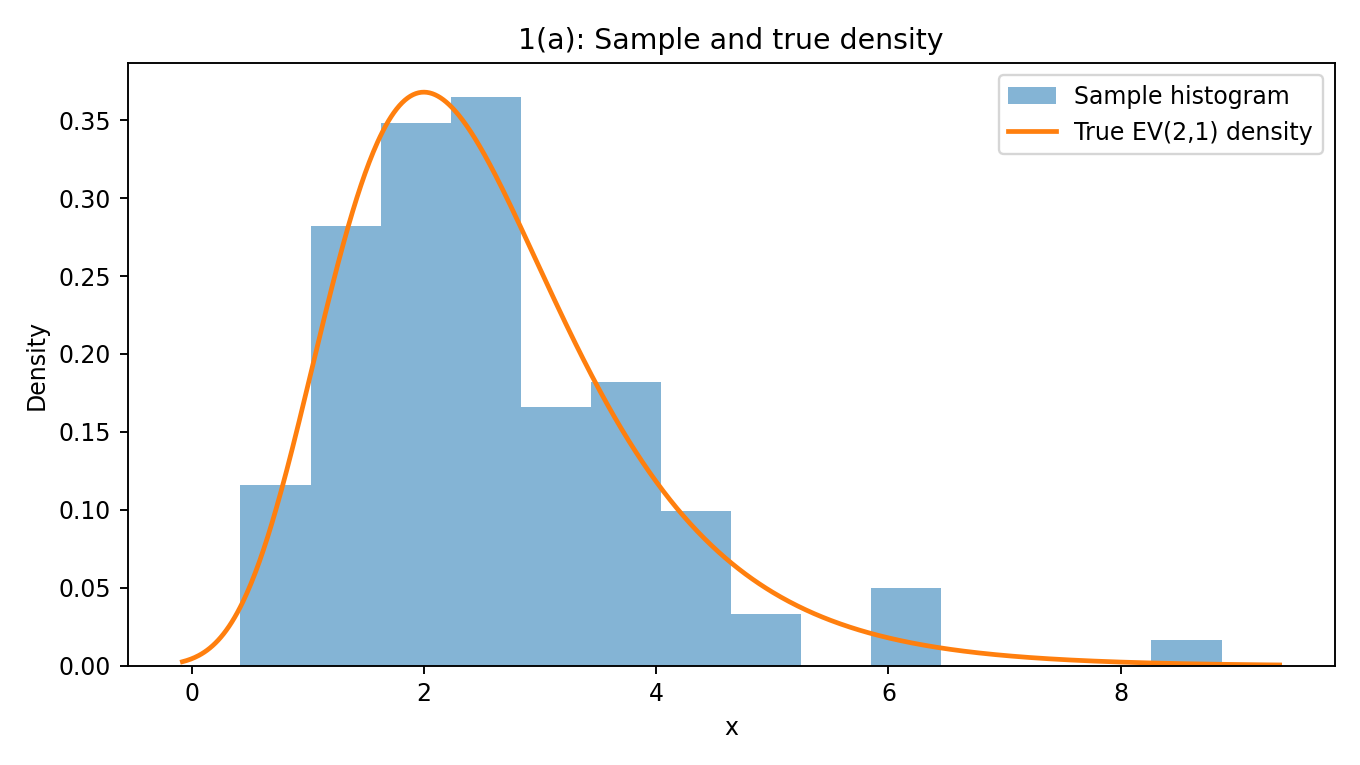

In [7]:
show_figure('1a_density.png')

**Empirical versus theoretical CDF**

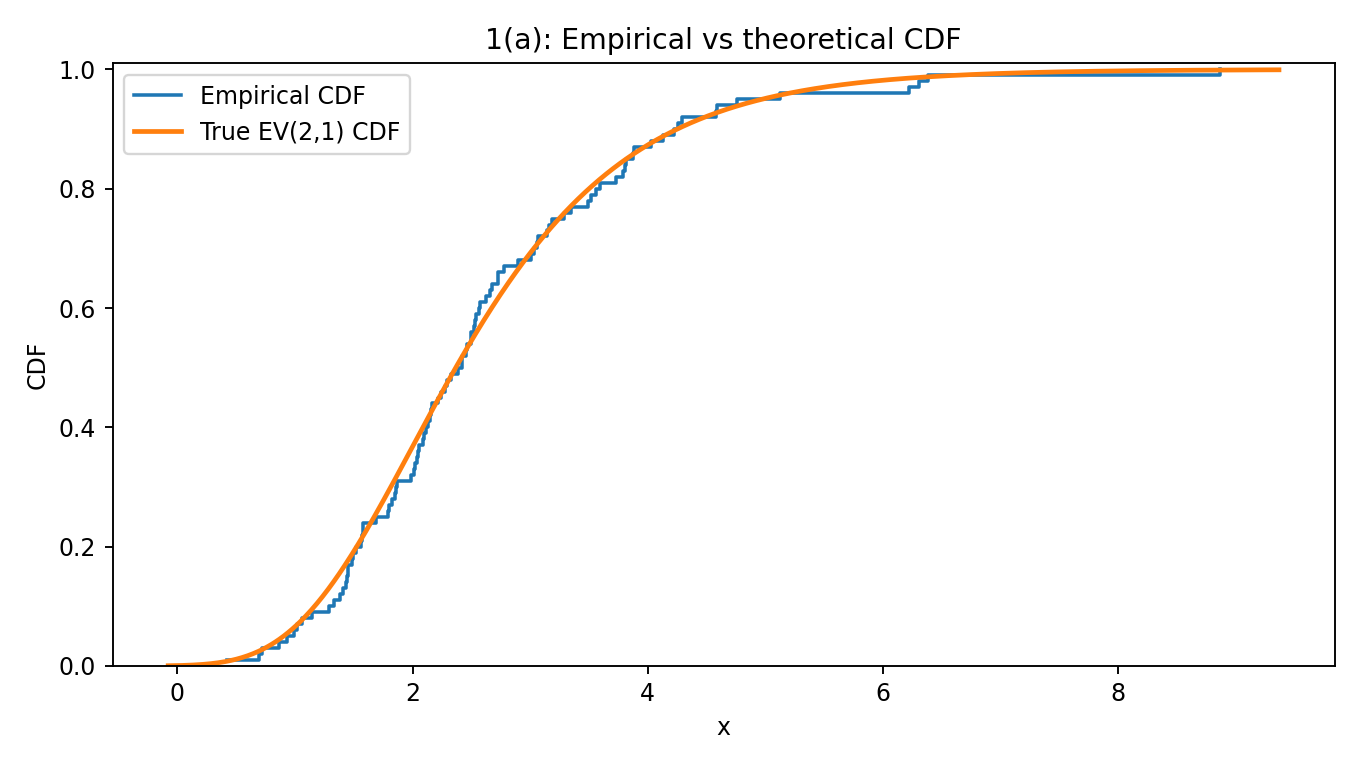

In [8]:
show_figure('1a_cdf.png')

**MCMC trace and burn-in cutoff**

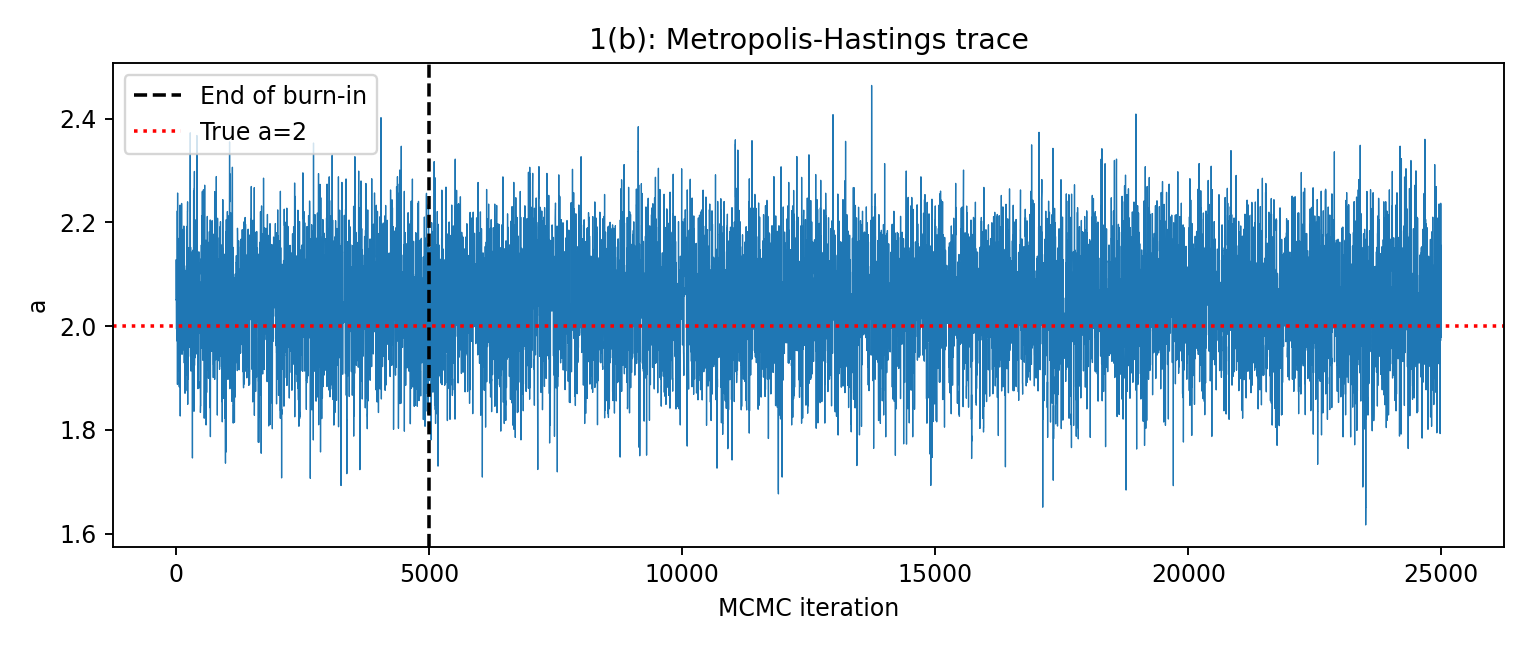

In [9]:
show_figure('1b_trace.png')

**Posterior histogram and exact density**

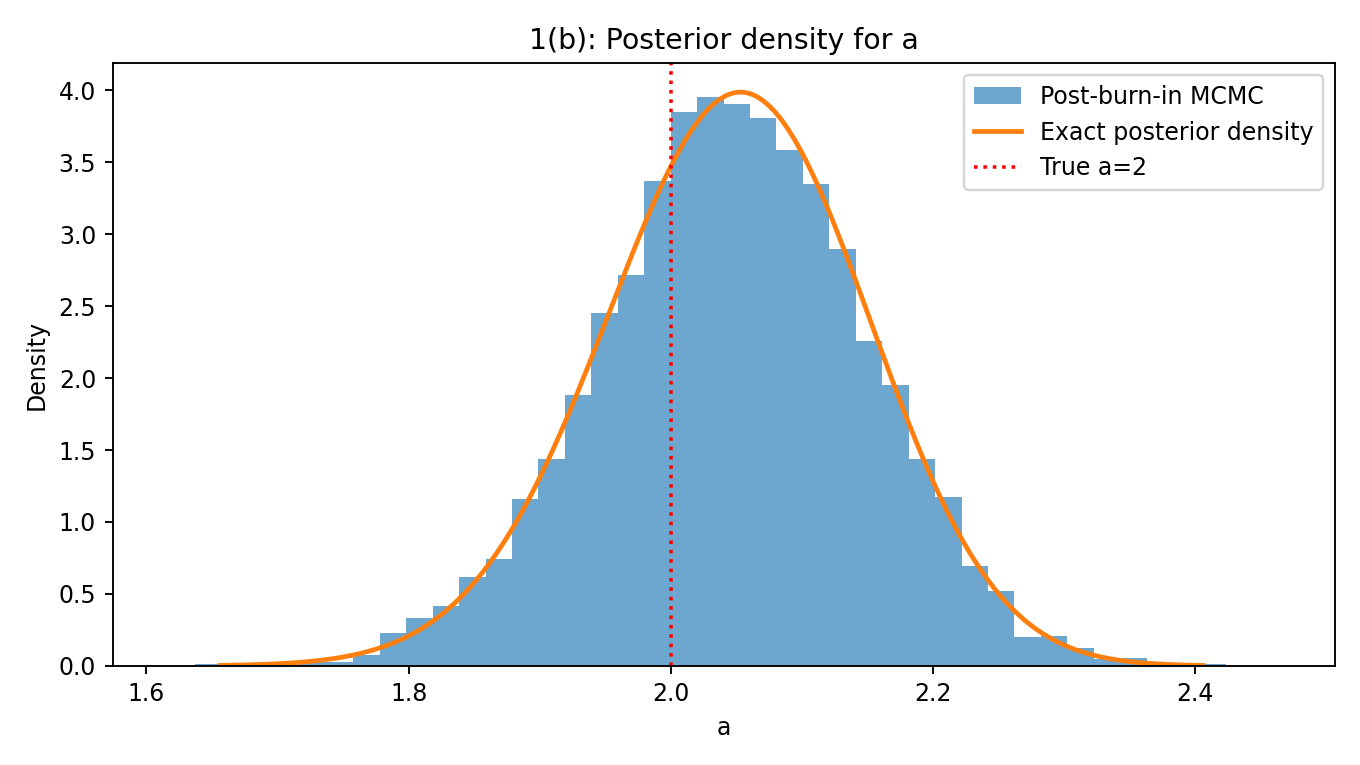

In [10]:
show_figure('1b_posterior.png')

### Discussion

The Gumbel distribution is right-skewed, so the histogram is not expected to be symmetric. With only 100 draws, departures from the exact density and CDF are ordinary sampling variation. Check the chain's trace for stability after burn-in and compare its density with the exact posterior. The 95% interval describes uncertainty about the **location parameter** under the stated flat prior, rather than a probability interval for a future observation.

# Problem 2 — Simulating Poisson variables from exponential waiting times

A Poisson process with rate $\lambda$ has independent interarrival times $Y_j\sim\operatorname{Exponential}(\text{rate}=\lambda)$, so their mean is $1/\lambda$ (NumPy's `scale` parameter). If $S_k=\sum_{j=1}^k Y_j$, the number of arrivals before time 1 is

$$Z=\#\{k:S_k<1\}\sim\operatorname{Poisson}(\lambda).$$

## Generate $N=1000$ observations, $\lambda=1$

**Algorithm for one count:** (1) initialize `time=0, count=0`; (2) draw an exponential waiting time and add it to `time`; (3) if `time<1`, increment `count` and repeat; (4) otherwise return `count`. Independently repeat 1,000 times. This is equivalent in distribution to counting arrivals in consecutive disjoint unit intervals of one Poisson process.

**Exact benchmark:** $P(Z=k)=e^{-\lambda}\lambda^k/k!$. We display counts in categories $0,1,\ldots,10,>10$ (that final category corresponds to 11 or more). A histogram of integer values should be treated as a *discrete probability histogram* or probability-mass chart.

In [11]:
def poisson_from_arrivals(n, rate=1., rng=RNG):
    """One unit interval per draw; count arrivals of a rate-lambda Poisson process."""
    out = np.empty(n, dtype=int)
    for i in range(n):
        t = 0.
        k = 0
        while True:
            t += rng.exponential(scale=1/rate)
            if t >= 1:
                break
            k += 1
        out[i] = k
    return out

## 2(a). Resampling method

**Step 1:** Generate the original 1,000 Poisson counts using arrival times.

**Step 2:** Independently select indices from the 1,000 observations *with replacement* to produce a large resample (100,000 counts in this illustration).

**Step 3:** Estimate $P(Z=k)$ by the relative resampled frequency in each category. This estimates the **empirical** distribution; it is a nonparametric bootstrap approach and cannot create previously unobserved count values.

## 2(b). Kernel density estimation method

Standard KDE creates a **continuous** density whereas Poisson data are **integer-valued**. To make a continuous KDE interpretable here:

1. Add $V_i\sim\operatorname{Uniform}(-0.5,0.5)$ to every observed count $Z_i$.
2. Fit a Gaussian KDE to the jittered values; for reproducibility, set the KDE bandwidth factor to 0.25 (a user choice, not mathematically optimal).
3. Convert the continuous fit to cell probabilities by integrating $\widehat f$ over $[k-0.5,k+0.5)$ for $k=0,\dots,10$, and over $[10.5,\infty)$ for the $>10$ bin.
4. Renormalize probability masses over valid nonnegative-count categories to account for Gaussian leakage below $-0.5$.

**Numeric comparison:** Compare all methods with the exact Poisson PMF using

$$\operatorname{RMSE}(\widehat p,p)=\sqrt{\frac1{12}\sum_{j=1}^{12}(\widehat p_j-p_j)^2}.$$

This comparison emphasizes probability-cell accuracy; KDE smoothing can help visualization but usually need not beat the empirical PMF for discrete counts.

In [12]:
def problem2():
    x = poisson_from_arrivals(1000, rate=1)
    # categories 0,..,10 and >10 (=11 or more); probability of >10 is tiny at lambda=1.
    observed = np.array([(x==k).sum() for k in range(11)]+[(x>10).sum()])
    theory = np.r_[stats.poisson.pmf(np.arange(11), mu=1), stats.poisson.sf(10, mu=1)]
    empirical = observed/len(x)
    # Resampling: nonparametric bootstrap of arrivals-based Poisson outcomes.
    bdraws = RNG.choice(x, size=100000, replace=True)
    bootstrap = np.array([(bdraws==k).mean() for k in range(11)]+[(bdraws>10).mean()])
    # KDE method: smooth jittered counts, then integrate density over category bins.
    # Without jitter, ordinary KDE is inappropriate at discrete integer spikes.
    jittered = x + RNG.uniform(-.5, .5, len(x))
    kde = stats.gaussian_kde(jittered, bw_method=.25)  # smoothing selected for display
    kde_p = np.array([kde.integrate_box_1d(k-.5,k+.5) for k in range(11)] +
                     [kde.integrate_box_1d(10.5, np.inf)])
    # Some KDE density lies below -0.5, so renormalize to valid count support.
    kde_p /= kde_p.sum()
    fig, ax = plt.subplots(figsize=(9,4.5))
    ks = np.arange(12)
    ax.bar(ks-.2, empirical, width=.4, label='Observed frequencies / N')
    ax.bar(ks+.2, theory, width=.4, label='Theoretical Poisson(1) PMF')
    ax.set(xticks=ks, xticklabels=[str(k) for k in range(11)]+['>10'], xlabel='Count per unit interval',ylabel='Probability', title='2: Poisson sample vs true PMF')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'2_pmf.png',dpi=170); plt.close(fig)
    fig, ax = plt.subplots(figsize=(9,4.5))
    ax.plot(ks, empirical, 'o-', label='Empirical')
    ax.plot(ks, theory, 's-', label='Theory')
    ax.plot(ks, bootstrap, '^--', label='Bootstrap resampling')
    ax.plot(ks, kde_p, 'd--', label='Integrated jittered KDE')
    ax.set(xticks=ks, xticklabels=[str(k) for k in range(11)]+['>10'],xlabel='Count', ylabel='Estimated probability', title='2: Discrete PMF estimates')
    ax.legend(); fig.tight_layout(); fig.savefig(OUT/'2_compare.png',dpi=170); plt.close(fig)
    rmse = lambda p: np.sqrt(np.mean((p-theory)**2))
    return {'counts 0..10, >10':observed, 'theory probabilities':theory,
            'empirical probabilities':empirical,
            'bootstrap probabilities':bootstrap,
            'KDE probabilities':kde_p,
            'empirical RMSE vs theoretical':rmse(empirical),
            'bootstrap RMSE vs theoretical':rmse(bootstrap),
            'KDE RMSE vs theoretical':rmse(kde_p),
            'sample mean':x.mean(),'sample variance':x.var(ddof=1)}

In [13]:
result2 = problem2()
for key, value in result2.items():
    print(f'{key}: {np.round(value, 7) if isinstance(value, np.ndarray) else value}')

counts 0..10, >10: [372 373 182  59   9   4   1   0   0   0   0   0]
theory probabilities: [3.678794e-01 3.678794e-01 1.839397e-01 6.131320e-02 1.532830e-02
 3.065700e-03 5.109000e-04 7.300000e-05 9.100000e-06 1.000000e-06
 1.000000e-07 0.000000e+00]
empirical probabilities: [0.372 0.373 0.182 0.059 0.009 0.004 0.001 0.    0.    0.    0.    0.   ]
bootstrap probabilities: [0.37345 0.37148 0.18267 0.05831 0.00923 0.00396 0.0009  0.      0.
 0.      0.      0.     ]
KDE probabilities: [3.480211e-01 3.652902e-01 1.949769e-01 7.127590e-02 1.464150e-02
 4.862300e-03 9.290000e-04 3.000000e-06 0.000000e+00 0.000000e+00
 0.000000e+00 0.000000e+00]
empirical RMSE vs theoretical: 0.0027910244189762734
bootstrap RMSE vs theoretical: 0.002780479491149209
KDE RMSE vs theoretical: 0.007222710084593867
sample mean: 0.976
sample variance: 0.9603843843843844


**Observed counts against theoretical Poisson probabilities**

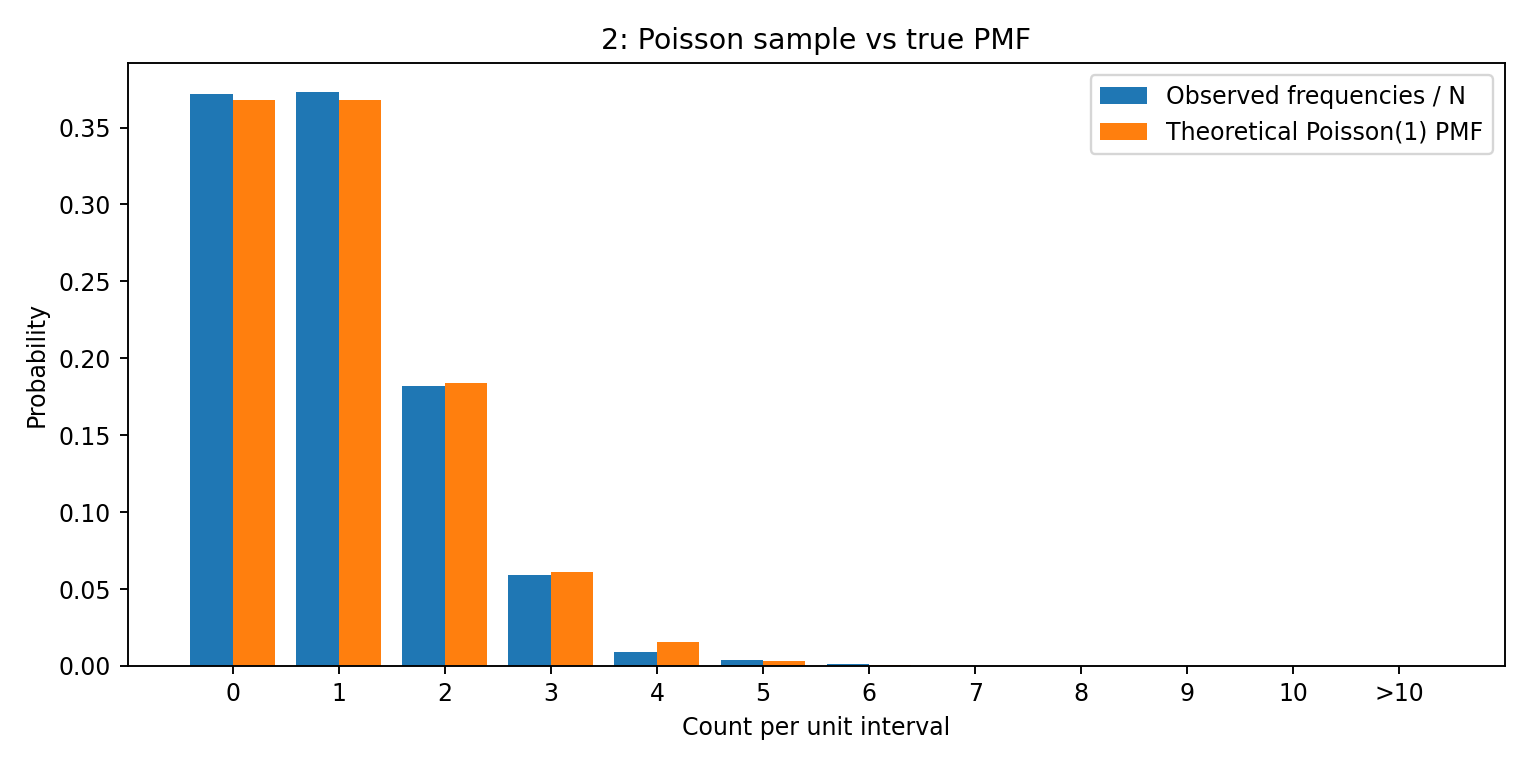

In [14]:
show_figure('2_pmf.png')

**Comparison of empirical, bootstrap, KDE, and theoretical probability masses**

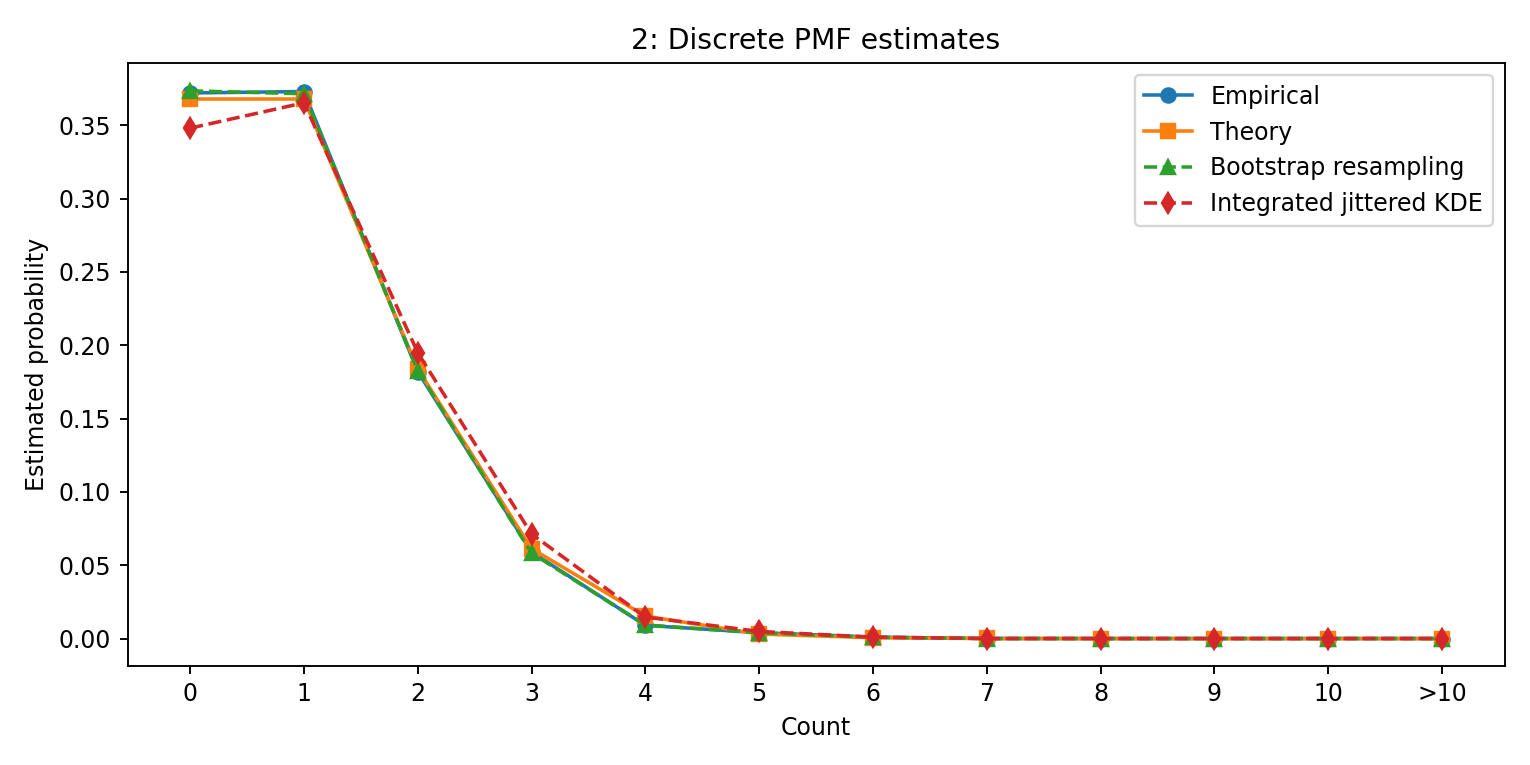

In [15]:
show_figure('2_compare.png')

### Discussion

For a Poisson(1) distribution, both the mean and variance should be 1. Compare those theoretical values to the empirical estimates displayed above. At $\lambda=1$, categories much larger than 5 are rare, so several zero-frequency categories are expected. Resampling closely follows the empirical histogram; KDE smooths the estimate across integer categories and may increase its RMSE despite producing a smoother-looking curve. The assignment's written label `10+` is ambiguous alongside a separate `10`; we consistently interpret the last bin as **strictly greater than 10**.

# Problem 3 — Gibbs sampling from conditional distributions

The assignment states

$$f(x\mid y)=y e^{-xy},\quad 0<x<10,\qquad f(y\mid x)=x e^{-xy},\quad 0<y<10.$$

## Step 1. Check the conditional normalization

On the stated support, $\int_0^{10}ye^{-xy}\,dx=1-e^{-10y}$, not 1. **Therefore the printed expressions are not normalized conditional PDFs on $(0,10)$.** We interpret them as *conditional kernels* and use the normalized truncated exponential distributions

$$p(x\mid y)=\frac{y e^{-xy}}{1-e^{-10y}},\qquad p(y\mid x)=\frac{x e^{-xy}}{1-e^{-10x}},\quad 0<x,y<10.$$

These correspond to the joint density

$$p(x,y)=\frac{e^{-xy}}{C}\mathbf 1_{(0,10)^2}(x,y),\quad C=\int_0^{10}\frac{1-e^{-10x}}{x}\,dx.$$

Integrating out $y$ gives the **exact marginal benchmark**

$$p(x)=\frac{1-e^{-10x}}{Cx},\quad 0<x<10.$$

The formulas above are a necessary normalization of the problem's stated kernels, not a claim that the original conditional expressions were already proper densities.

## Step 2. Derive the conditional inverse transform

For $X\mid Y=y$, the truncated-exponential CDF is

$$F(x\mid y)=\frac{1-e^{-yx}}{1-e^{-10y}}.$$

Solving $U=F(x\mid y)$, where $U\sim\operatorname{Uniform}(0,1)$, gives

$$X=-\frac{\log\left(1-U(1-e^{-10y})\right)}{y}.$$

Use the analogous expression when sampling $Y\mid X=x$. At rate 0, the continuous limit is Uniform$(0,10)$.

## Step 3. Design and run the Gibbs sampler

1. Initialize $(x_0,y_0)$ to a chosen point inside $(0,10)^2$.
2. Draw $x_{t+1}\sim p(x\mid y_t)$.
3. Draw $y_{t+1}\sim p(y\mid x_{t+1})$.
4. Repeat for 3,000 burn-in sweeps, then retain every fifth subsequent $x$ until there are 1,000 retained values.
5. Repeat the entire procedure from $(0.2,0.2)$ and $(9.5,9.5)$ to check sensitivity to different initial states.

**Step 4. Summary estimators:** sample mean, sample variance (denominator $n-1$), bias-corrected skewness, and **Pearson kurtosis** (normal distribution equals 3, not excess kurtosis). Use a reflected Gaussian KDE for density estimates at $0.1,1.8,3.5,9.2$.

**Caution:** Boundary-reflection KDE can still have substantial bias at 0.1 because this marginal rises very sharply near zero. Use the exact marginal density as a reference and do not report the KDE estimate as an exact value.

In [16]:
def truncated_exponential(rate, upper=10., rng=RNG):
    """Inverse CDF of truncated Exp(rate) supported on (0,upper)."""
    u = rng.random()
    if rate < 1e-10:  # conditional approaches Uniform(0,upper)
        return upper*u
    return -np.log1p(-u*(-np.expm1(-rate*upper)))/rate

def gibbs_xy(x0,y0,n=1000,burn=3000,thin=5,rng=RNG):
    x,y=float(x0),float(y0)
    xs=[]
    full_trace=[]
    total=burn+n*thin
    for j in range(total):
        x = truncated_exponential(y,rng=rng)
        y = truncated_exponential(x,rng=rng)
        if j >= burn and (j-burn)%thin == 0:
            xs.append(x)
        if j < burn or j % thin == 0:
            full_trace.append(x)
    return np.asarray(xs),np.asarray(full_trace)

def marginal_x_pdf(x):
    """Under the normalized joint f(x,y) proportional to exp(-xy) on (0,10)^2."""
    if x <= 0 or x >= 10: return 0.
    return (-np.expm1(-10*x))/x/NORMALIZER

NORMALIZER = quad(lambda t: 10 if t == 0 else -np.expm1(-10*t)/t, 0, 10,
                  epsabs=1e-12)[0]

def summarize_gibbs(a):
    return dict(mean=np.mean(a), variance=np.var(a,ddof=1),
                skewness=stats.skew(a,bias=False),
                kurtosis=stats.kurtosis(a,fisher=False,bias=False))

In [17]:
def problem3():
    eval_points=np.array([.1,1.8,3.5,9.2])
    theory_pdf=np.array([marginal_x_pdf(t) for t in eval_points])
    results={}
    truegrid=np.linspace(.0001,9.9999,600)
    for label, (x0,y0) in [('A',(0.2,0.2)),('B',(9.5,9.5))]:
        x,trace=gibbs_xy(x0,y0)
        kde=stats.gaussian_kde(x)
        # Boundary-corrected (reflection) KDE; avoids leaking density to x<0 and x>10.
        h=kde.factor*np.std(x,ddof=1)
        def reflected_density(query):
            query=np.asarray(query)
            z=(query[:,None]-x[None,:])/h
            z_left=(query[:,None]+x[None,:])/h
            z_right=(query[:,None]-(20-x[None,:]))/h
            return (stats.norm.pdf(z)+stats.norm.pdf(z_left)+stats.norm.pdf(z_right)).mean(axis=1)/h
        den=reflected_density(eval_points)
        fig, axs=plt.subplots(2,1,figsize=(9,7))
        axs[0].plot(np.arange(len(x)),x,lw=.65)
        axs[0].set(title=f'3: Gibbs chain {label} (after burn-in, thinned)',xlabel='Retained iteration',ylabel='x')
        axs[1].hist(x,bins=35,density=True,alpha=.5,label='Histogram')
        axs[1].plot(truegrid, [marginal_x_pdf(t) for t in truegrid],lw=2,label='Normalized theoretical marginal')
        axs[1].plot(truegrid,reflected_density(truegrid),lw=1.5,linestyle='--',label='Reflection KDE')
        axs[1].set(xlabel='x',ylabel='Density',ylim=(0,None))
        axs[1].legend()
        fig.tight_layout(); fig.savefig(OUT/f'3_gibbs_{label}.png',dpi=170);plt.close(fig)
        results[label]={'start':(x0,y0),**summarize_gibbs(x),'estimated pdf at [0.1,1.8,3.5,9.2]':den}
    # exact moments for comparison
    moms=[quad(lambda z: z**k*marginal_x_pdf(z),0,10)[0] for k in range(1,5)]
    mu=moms[0]; var=moms[1]-mu**2
    skew=(moms[2]-3*mu*moms[1]+2*mu**3)/var**1.5
    kurt=(moms[3]-4*mu*moms[2]+6*mu**2*moms[1]-3*mu**4)/var**2
    results['theory']={'mean':mu,'variance':var,'skewness':skew,'kurtosis':kurt,
                       'pdf at [0.1,1.8,3.5,9.2]':theory_pdf}
    return results

In [18]:
result3 = problem3()
points = [0.1, 1.8, 3.5, 9.2]
for label, info in result3.items():
    print(f'\n{label}:')
    for key, value in info.items():
        print(f'  {key}: {np.round(value, 6) if isinstance(value, np.ndarray) else value}')
print('\nRequested density locations:', points)


A:
  start: (0.2, 0.2)
  mean: 1.984474606130567
  variance: 6.305135370669112
  skewness: 1.4580627374958033
  kurtosis: 4.0736493795747
  estimated pdf at [0.1,1.8,3.5,9.2]: [0.600734 0.126863 0.054172 0.020014]

B:
  start: (9.5, 9.5)
  mean: 1.8266120273656867
  variance: 5.477989214422482
  skewness: 1.5466682532216993
  kurtosis: 4.464542680608788
  estimated pdf at [0.1,1.8,3.5,9.2]: [0.644272 0.1253   0.054428 0.015624]

theory:
  mean: 1.9103170402297496
  variance: 5.9968250523821105
  skewness: 1.5649146042294022
  kurtosis: 4.509618681665639
  pdf at [0.1,1.8,3.5,9.2]: [1.219748 0.107201 0.055132 0.020974]

Requested density locations: [0.1, 1.8, 3.5, 9.2]


**Chain A: trace and density, initialized at (0.2,0.2)**

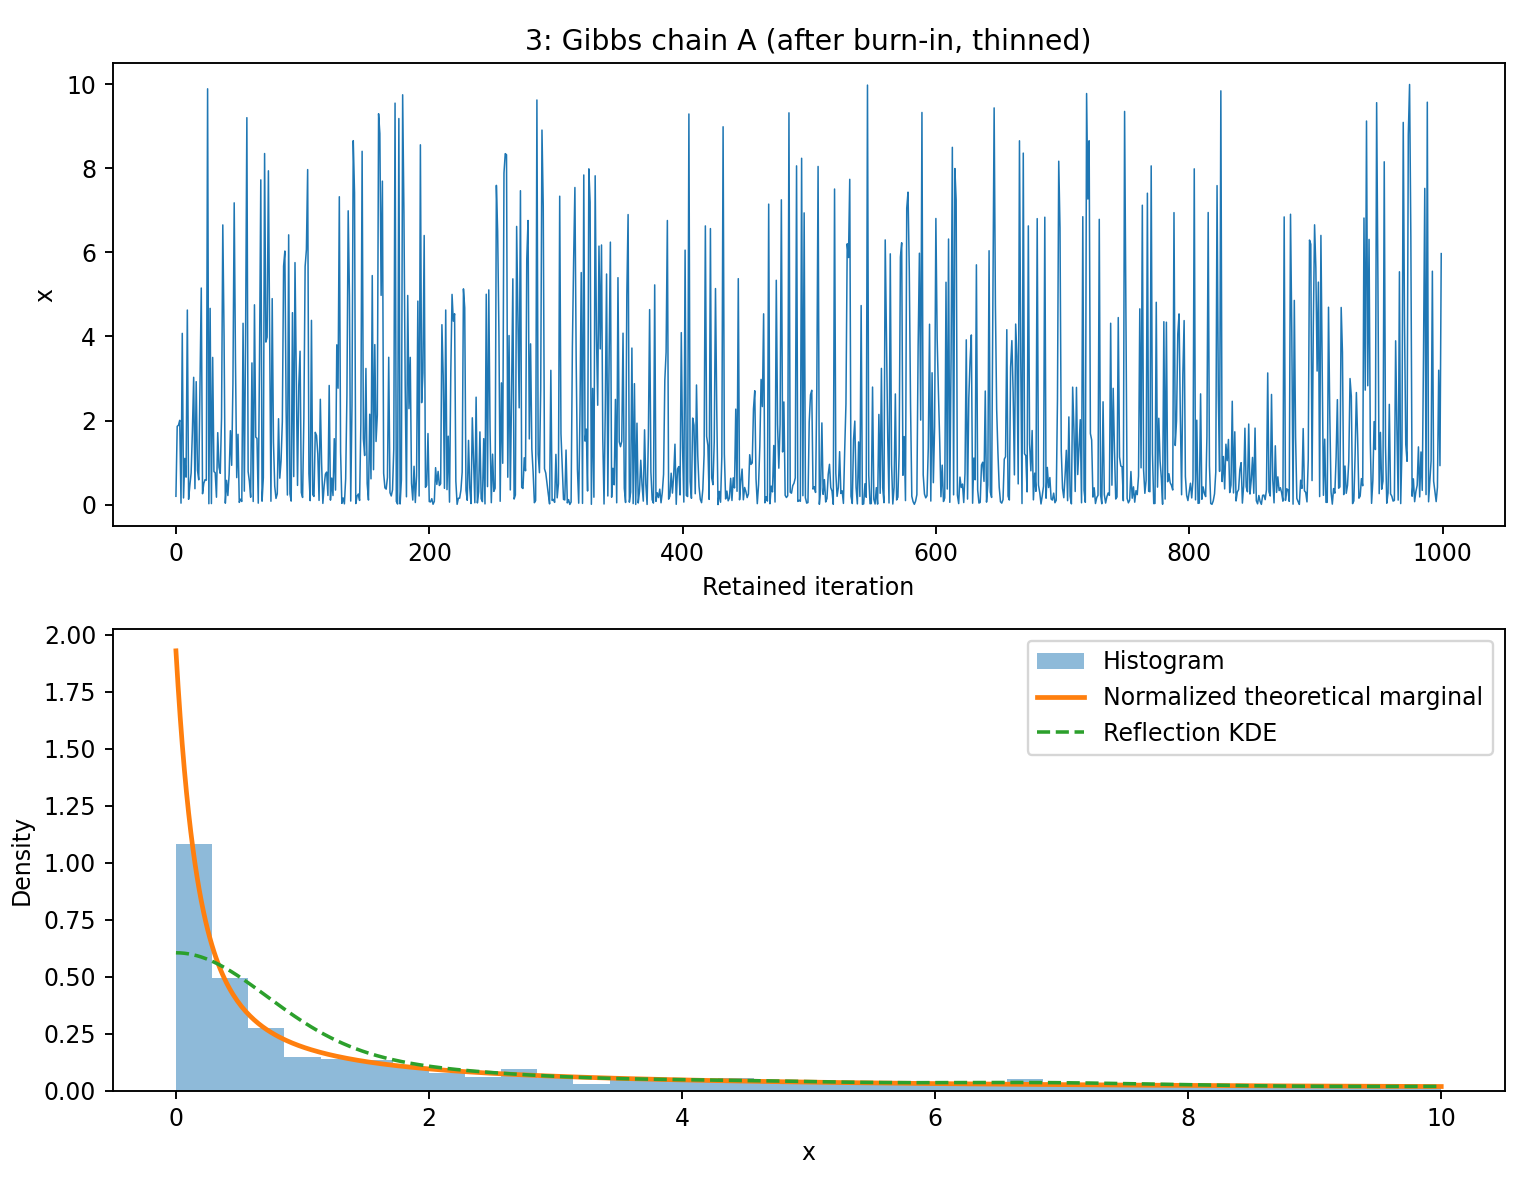

In [19]:
show_figure('3_gibbs_A.png')

**Chain B: trace and density, initialized at (9.5,9.5)**

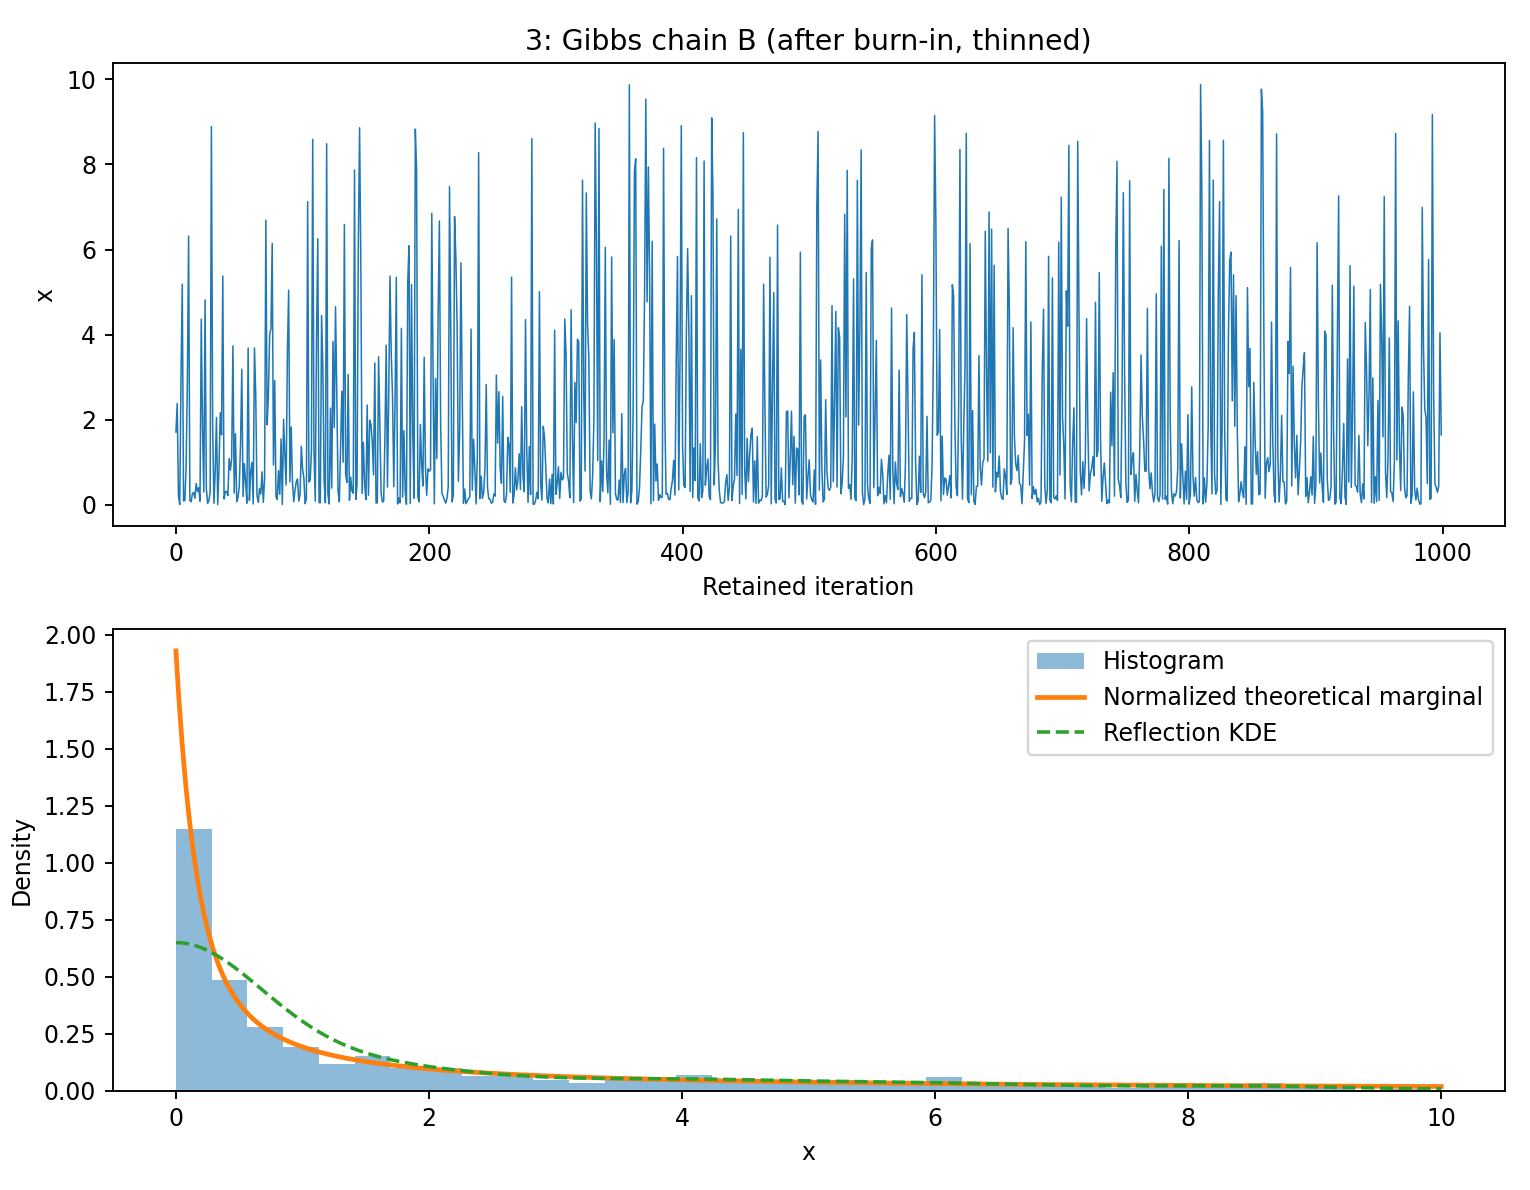

In [20]:
show_figure('3_gibbs_B.png')

## Step 5. Exact moments for cross-checking

Using numerical integration and $p(x)$, define the raw moments $m_r=\int_0^{10}x^r p(x)\,dx$. Then

$$\mu=m_1,\qquad \sigma^2=m_2-m_1^2,$$

$$\text{skewness}=\frac{m_3-3m_1m_2+2m_1^3}{\sigma^3},$$

$$\text{Pearson kurtosis}=\frac{m_4-4m_1m_3+6m_1^2m_2-3m_1^4}{\sigma^4}.$$

The `problem3()` function implements these integrations and prints theoretical values for direct comparison with both chains.

### Discussion

Different initialization points can affect early sweeps, motivating burn-in and chain comparison. The retained estimates should be broadly consistent, but **agreement between two chains does not prove convergence**. With only 1,000 retained samples, Monte Carlo error can be visible in high-order moments and the upper tail. In particular, expect the density estimate at $x=0.1$ to differ from the theoretical value more than interior estimates because of sharp boundary behavior.

# Final interpretation and reproducibility checklist

- **Problem 1:** Inverse-transform simulation generates EV(2,1) observations, while Metropolis–Hastings estimates unknown $a$ using the same observations and an explicitly stated flat prior.
- **Problem 2:** Arrival-time counts yield Poisson pseudo-random variables. Empirical/bootstrapped probabilities and integrated KDE are compared with the exact Poisson(1) probabilities graphically and using RMSE.
- **Problem 3:** Properly normalized finite-interval conditionals are used for two Gibbs chains. We report descriptive moments, density estimates at all four requested points, chain plots, and exact-reference calculations.

**How to reproduce:** Restart kernel → Run All. Saved figures will be written to the local `results/` directory. Because one shared seeded generator is used, running selected sections in a different order can produce different numerical samples; Run All preserves the results in the recorded order.